DATA LOADING AND ASSESSMENT

In [ ]:
import pandas as pd

data = pd.read_csv('Recipe Reviews and User Feedback Dataset.csv')

# Load and Assemessment of the Dataset
print("DATA LOADING AND ASSESSMENT")

# Initial Exploration of the Dataset
print(data.head())
print(data.info())
print(data.isna().sum())
print(data.duplicated().sum())
print(data.describe(include='all'))

# Deeper Analysis of the Dataset
print((data['stars'] == 0).sum(), data['stars'].value_counts().sort_index())
print(pd.to_datetime(data['created_at'], unit='s').describe())
print(data['text'].duplicated().sum())
print(data.duplicated(subset=['user_id', 'recipe_code', 'text']).sum())
print(data.groupby('recipe_code')['recipe_name'].nunique().max())
print(data['best_score'].value_counts().head())

DATA CLEANING AND PREPROCESSING

In [3]:
import pandas as pd
import numpy as np
import re
import html

data = pd.read_csv('../data/Recipe Reviews and User Feedback Dataset.csv')

# Data Cleaning and Preprocessing
print("DATA CLEANING AND PREPROCESSING")

log = []  # decision log
n0 = len(data)

# 1. Standardize column names and drop the per-recipe comment index
data.columns = (data.columns.str.strip().str.lower()
                .str.replace(r'\s+', '_', regex=True))
data = data.drop(columns=['number'])
log.append(('Column names', 'Already mostly snake_case; stripped/lowercased; dropped "number"',
            'It is a per-recipe comment index, not an identifier'))

# 2. Data types
data['created_at'] = pd.to_datetime(data['created_at'], unit='s')
for c in ['recipe_code', 'recipe_number']:
    data[c] = data[c].astype(str) if c == 'recipe_code' else data[c]
log.append(('created_at', 'Converted Unix seconds to datetime',
            'Needed for date features; note most values cluster on 2021-06-03'))

# 3. Text cleaning and missing text
def clean_text(t):
    if not isinstance(t, str):
        return t
    t = html.unescape(t)                      # &#34; -> ", &amp; -> &
    t = re.sub(r'<br\s*/?>', ' ', t, flags=re.I)   # line-break tags -> space
    t = re.sub(r'</?[a-zA-Z][^>]*>', ' ', t)  # remove <p>, </p>, <b>, <a href=...> etc.
    t = html.unescape(t)                      # in case entities were double-encoded
    t = re.sub(r'\s+', ' ', t).strip()        # newlines/tabs/extra spaces -> one space
    return t

data['text'] = data['text'].apply(clean_text)
data['text'] = data['text'].replace('', np.nan)   # reviews that were only tags/whitespace
n_missing_text = data['text'].isna().sum()
data = data.dropna(subset=['text'])
log.append(('Text formatting',
            'Unescaped HTML entities, stripped HTML tags, collapsed newlines and repeated spaces',
            'Needed for accurate review length/word count and readable CSV'))

# 4. Invalid ratings: stars = 0 means "no rating"
data['stars_valid'] = data['stars'].replace(0, np.nan)
log.append(('stars = 0', f'{(data["stars"]==0).sum()} rows set to NaN in stars_valid (rows kept)',
            'Scale is 1-5; 0 means no rating. Kept for engagement analysis, excluded from rating stats and ML'))

# 5. Duplicates
before = len(data)
data = data.drop_duplicates(subset=['user_id', 'recipe_code', 'text'])
log.append(('Duplicates', f'Removed {before-len(data)} rows with same user, recipe and text',
            'Likely repeated posts; identical short text from different users was kept'))

# 6. Validation checks
assert data['comment_id'].is_unique
assert data.groupby('recipe_code')['recipe_name'].nunique().max() == 1
assert (data[['thumbs_up','thumbs_down','reply_count','user_reputation']] >= 0).all().all()
assert data['stars'].between(0, 5).all()

# Outliers in votes/reputation are kept (they look genuine); log-transform later if modeling
log.append(('Outliers', 'Kept thumbs_up/thumbs_down/user_reputation outliers',
            'Plausible values, not errors'))

# best_score is mostly default 100, so exclude it from ML features
log.append(('best_score', 'Kept but excluded from ML features',
            '77% equal 100; likely derived from votes, so it could leak'))

print(f'Rows: {n0} -> {len(data)} after cleaning')
decision_log = pd.DataFrame(log, columns=['Issue', 'Action', 'Reason'])
print(decision_log.to_string(index=False))

data.to_csv('../data/recipe_reviews_clean.csv', index=False)

DATA CLEANING AND PREPROCESSING
Rows: 18182 -> 17804 after cleaning
          Issue                                                                              Action                                                                                           Reason
   Column names                    Already mostly snake_case; stripped/lowercased; dropped "number"                                              It is a per-recipe comment index, not an identifier
     created_at                                                  Converted Unix seconds to datetime                                 Needed for date features; note most values cluster on 2021-06-03
Text formatting Unescaped HTML entities, stripped HTML tags, collapsed newlines and repeated spaces                                    Needed for accurate review length/word count and readable CSV
      stars = 0                                     1695 rows set to NaN in stars_valid (rows kept) Scale is 1-5; 0 means no rating. Kept for en

RELATIONAL DATABASE DESIGN and SQL

In [7]:
import pandas as pd
import sqlite3

data = pd.read_csv('../data/recipe_reviews_clean.csv', parse_dates=['created_at'])

# Decompose into recipes, users, and reviews tables
print(data.groupby('user_id')['user_name'].nunique().max())
print(data.groupby('user_id')['user_reputation'].nunique().max())
print(data.groupby('recipe_code')['recipe_name'].nunique().max())

recipes = (data[['recipe_code', 'recipe_number', 'recipe_name']]
           .drop_duplicates('recipe_code')
           .reset_index(drop=True))

users = (data.groupby('user_id')
           .agg(user_name=('user_name', 'first'),
                user_reputation=('user_reputation', 'max'))
           .reset_index())

reviews = data[['comment_id', 'recipe_code', 'user_id', 'created_at',
              'stars', 'stars_valid', 'thumbs_up', 'thumbs_down',
              'reply_count', 'best_score', 'text']].copy()
reviews['created_at'] = reviews['created_at'].dt.strftime('%Y-%m-%d %H:%M:%S')

print(len(recipes), len(users), len(reviews))

# Create SQLite database and tables for recipes, users, and reviews
conn = sqlite3.connect('../data/recipe_reviews.db')
conn.execute('PRAGMA foreign_keys = ON')
cur = conn.cursor()

cur.executescript('''
DROP TABLE IF EXISTS reviews;
DROP TABLE IF EXISTS users;
DROP TABLE IF EXISTS recipes;

CREATE TABLE recipes (
    recipe_code   INTEGER PRIMARY KEY,
    recipe_number INTEGER NOT NULL,
    recipe_name   TEXT NOT NULL
);

CREATE TABLE users (
    user_id         TEXT PRIMARY KEY,
    user_name       TEXT,
    user_reputation INTEGER
);

CREATE TABLE reviews (
    comment_id   TEXT PRIMARY KEY,
    recipe_code  INTEGER NOT NULL,
    user_id      TEXT NOT NULL,
    created_at   TEXT,
    stars        INTEGER CHECK (stars BETWEEN 0 AND 5),
    stars_valid  REAL,
    thumbs_up    INTEGER,
    thumbs_down  INTEGER,
    reply_count  INTEGER,
    best_score   INTEGER,
    text         TEXT,
    FOREIGN KEY (recipe_code) REFERENCES recipes(recipe_code),
    FOREIGN KEY (user_id)     REFERENCES users(user_id)
);
''')

recipes.to_sql('recipes', conn, if_exists='append', index=False)
users.to_sql('users', conn, if_exists='append', index=False)
reviews.to_sql('reviews', conn, if_exists='append', index=False)
conn.commit()

print(pd.read_sql_query('SELECT COUNT(*) AS n FROM reviews', conn))

#SQL queries to check the data
def q(sql):
    return pd.read_sql_query(sql, conn)

q('''
SELECT comment_id, recipe_code, stars, thumbs_up
FROM reviews
WHERE stars = 5 AND thumbs_up >= 10
ORDER BY thumbs_up DESC
LIMIT 10;
''')

q('''
SELECT COUNT(*)                         AS total_reviews,
       COUNT(stars_valid)               AS rated_reviews,
       ROUND(AVG(stars_valid), 3)       AS avg_rating,
       SUM(thumbs_up)                   AS total_thumbs_up,
       SUM(thumbs_down)                 AS total_thumbs_down
FROM reviews;
''')

q('''
SELECT r.recipe_name,
       COUNT(*)                   AS n_reviews,
       ROUND(AVG(v.stars_valid), 3) AS avg_rating,
       SUM(v.thumbs_up)           AS total_thumbs_up
FROM reviews v
JOIN recipes r ON r.recipe_code = v.recipe_code
GROUP BY r.recipe_code, r.recipe_name
HAVING COUNT(v.stars_valid) >= 50
ORDER BY avg_rating DESC
LIMIT 10;
''')

q('''
SELECT r.recipe_name, u.user_name, u.user_reputation,
       v.stars, v.thumbs_up, v.thumbs_down
FROM reviews v
JOIN recipes r ON r.recipe_code = v.recipe_code
JOIN users   u ON u.user_id     = v.user_id
ORDER BY v.thumbs_up DESC
LIMIT 10;
''')

q('''
SELECT u.user_id, u.user_name, COUNT(*) AS n_reviews,
       ROUND(AVG(v.stars_valid), 2) AS avg_rating
FROM reviews v
JOIN users u ON u.user_id = v.user_id
GROUP BY u.user_id, u.user_name
ORDER BY n_reviews DESC
LIMIT 10;
''')

q('''
SELECT recipe_name, user_name, thumbs_up, rnk
FROM (
    SELECT r.recipe_name, u.user_name, v.thumbs_up,
           RANK() OVER (PARTITION BY v.recipe_code
                        ORDER BY v.thumbs_up DESC) AS rnk
    FROM reviews v
    JOIN recipes r ON r.recipe_code = v.recipe_code
    JOIN users   u ON u.user_id     = v.user_id
)
WHERE rnk <= 3
ORDER BY recipe_name, rnk;
''')

q('''
WITH recipe_stats AS (
    SELECT r.recipe_name,
           COUNT(v.stars_valid)       AS n_rated,
           AVG(v.stars_valid)         AS avg_rating
    FROM reviews v
    JOIN recipes r ON r.recipe_code = v.recipe_code
    GROUP BY r.recipe_code, r.recipe_name
    HAVING COUNT(v.stars_valid) >= 50
)
SELECT recipe_name,
       ROUND(avg_rating, 3) AS avg_rating,
       ROUND(avg_rating - AVG(avg_rating) OVER (), 3) AS diff_from_mean,
       RANK() OVER (ORDER BY avg_rating DESC) AS rating_rank
FROM recipe_stats
ORDER BY rating_rank
LIMIT 10;
''')

q('''
SELECT user_id, created_at,
       ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY created_at) AS nth_review
FROM reviews
WHERE user_id IN (SELECT user_id FROM reviews GROUP BY user_id HAVING COUNT(*) >= 5)
ORDER BY user_id, created_at
LIMIT 20;
''')

conn.close()

1
5
1
100 13811 17804
       n
0  17804


FEATURE ENGINEERING & PROBABILITY/STATISTIC ANALYSIS

       review_length    word_count   total_votes     net_votes   high_rating
count   16167.000000  16167.000000  16167.000000  16167.000000  16167.000000
mean      203.622688     38.523288      1.540917      0.536649      0.838436
std       171.931015     32.734581      5.993928      4.068007      0.368061
min         1.000000      1.000000      0.000000   -121.000000      0.000000
25%        89.000000     17.000000      0.000000      0.000000      1.000000
50%       162.000000     30.000000      0.000000      0.000000      1.000000
75%       266.000000     51.000000      1.000000      0.000000      1.000000
max      2689.000000    499.000000    157.000000    103.000000      1.000000
high_rating
1    0.838436
0    0.161564
Name: proportion, dtype: float64
P(high rating) = 0.838
                           probability
P(high | long review)            0.824
P(high | short review)           0.852
P(high | has votes)              0.782
P(high | no votes)               0.859
P(high | has thu

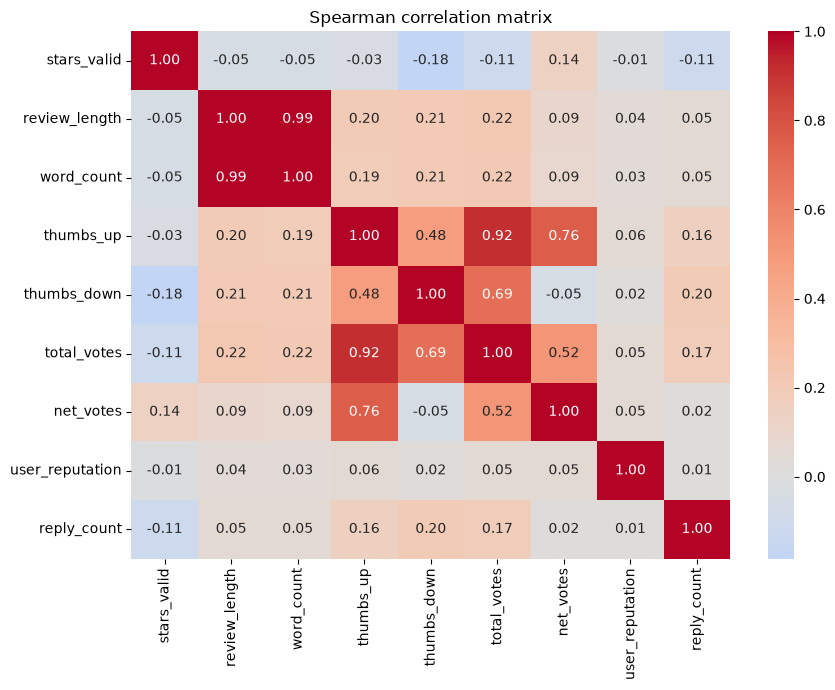

Mann-Whitney U = 16405481.5, p = 2.85e-09
Median length: high = 159.0, not high = 176.0


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

data = pd.read_csv('../data/recipe_reviews_clean.csv', parse_dates=['created_at'])

# Text features (text was already cleaned of HTML and newlines)
data['review_length'] = data['text'].str.len()
data['word_count']    = data['text'].str.split().str.len()

# Vote features
data['total_votes'] = data['thumbs_up'] + data['thumbs_down']
data['net_votes']   = data['thumbs_up'] - data['thumbs_down']
data['has_votes']   = (data['total_votes'] > 0).astype(int)

# Date components
data['year']      = data['created_at'].dt.year
data['month']     = data['created_at'].dt.month
data['day_of_week'] = data['created_at'].dt.day_name()
data['hour']      = data['created_at'].dt.hour

# High-rating indicator (NaN where there is no valid rating)
HIGH_THRESHOLD = 5   # try 4 for "4 stars or more"; justify your choice in the report
data['high_rating'] = np.where(data['stars_valid'].isna(), np.nan,
                               (data['stars_valid'] >= HIGH_THRESHOLD).astype(float))

rated = data[data['stars_valid'].notna()].copy()
rated['high_rating'] = rated['high_rating'].astype(int)

print(rated[['review_length','word_count','total_votes','net_votes','high_rating']].describe())
print(rated['high_rating'].value_counts(normalize=True))

data.to_csv('../data/recipe_reviews_features.csv', index=False)


### PROBABILITY AND STATISTICS ANALYSIS

# Probability of high rating and conditional probabilities
p_high = rated['high_rating'].mean()
print(f'P(high rating) = {p_high:.3f}')

median_len = rated['review_length'].median()
rated['long_review'] = (rated['review_length'] > median_len).astype(int)
rated['has_thumbs_down'] = (rated['thumbs_down'] > 0).astype(int)

cond = pd.DataFrame({
    'P(high | long review)':       [rated.loc[rated.long_review==1, 'high_rating'].mean()],
    'P(high | short review)':      [rated.loc[rated.long_review==0, 'high_rating'].mean()],
    'P(high | has votes)':         [rated.loc[rated.has_votes==1, 'high_rating'].mean()],
    'P(high | no votes)':          [rated.loc[rated.has_votes==0, 'high_rating'].mean()],
    'P(high | has thumbs down)':   [rated.loc[rated.has_thumbs_down==1, 'high_rating'].mean()],
    'P(high | no thumbs down)':    [rated.loc[rated.has_thumbs_down==0, 'high_rating'].mean()],
}).T.rename(columns={0: 'probability'})
print(cond.round(3))

# Joint / cross-tab view
print(pd.crosstab(rated['long_review'], rated['high_rating'], normalize='index').round(3))

# Summary of numeric features for rated reviews
cols = ['stars_valid','review_length','word_count','thumbs_up','thumbs_down',
        'total_votes','net_votes','user_reputation','reply_count']
summary = rated[cols].describe().T
summary['median'] = rated[cols].median()
summary['skew'] = rated[cols].skew()
print(summary.round(3))

# Approximate 95% confidence intervals 
n = len(rated)

# Proportion of high ratings
se_p = np.sqrt(p_high * (1 - p_high) / n)
ci_p = (p_high - 1.96*se_p, p_high + 1.96*se_p)
print(f'High-rating proportion: {p_high:.3f}, 95% CI = ({ci_p[0]:.3f}, {ci_p[1]:.3f})')

# Mean star rating
m, s = rated['stars_valid'].mean(), rated['stars_valid'].std(ddof=1)
se_m = s / np.sqrt(n)
print(f'Mean rating: {m:.3f}, 95% CI = ({m-1.96*se_m:.3f}, {m+1.96*se_m:.3f})')

# Correlation
corr_cols = ['stars_valid','review_length','word_count','thumbs_up','thumbs_down',
             'total_votes','net_votes','user_reputation','reply_count']
print(rated[corr_cols].corr(method='pearson').round(2))
print(rated[corr_cols].corr(method='spearman').round(2))


plt.figure(figsize=(9, 7))
sns.heatmap(rated[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman correlation matrix')
plt.tight_layout(); plt.show()

# Hypothesis Tests

high = rated.loc[rated.high_rating==1, 'review_length']
low  = rated.loc[rated.high_rating==0, 'review_length']

# H0: review length has the same distribution for high and non-high ratings
# H1: the distributions differ (two-sided), alpha = 0.05
u, p = stats.mannwhitneyu(high, low, alternative='two-sided')
print(f'Mann-Whitney U = {u:.1f}, p = {p:.3g}')
print(f'Median length: high = {high.median()}, not high = {low.median()}')
